# Unit 11: Model Performance Measurement, second run
The brief asks me to run the supplied `model_Performance_Measurement.ipynb`, change different parameters, and observe the impact on AUC and R².

This second run keeps my first run's questions and fixes its method. Settings are now **chosen by cross-validation on the training data only**, and each chosen model is **tested once** on data it never saw; the parameter sweeps are shown as cross-validation sensitivity, not tested on the held-out set. It adds baselines, repeats the noise experiment over five random seeds with nested noise columns, and reports the rank of the cubic design.

**Part 1** runs the supplied cells in order. Three cells needed a change, recorded where it happens:
- the accuracy cell started with a space, which Python rejects (IndentationError);
- the multiclass AUC cell is wrapped in `OneVsRestClassifier`, to make the one-versus-rest strategy explicit and compatible with newer scikit-learn versions, which no longer accept `liblinear` for three classes;
- the cell headed "RMSE" calculates the mean squared error (MSE); I keep it and add the square root, which is the RMSE.

All data sets ship with scikit-learn, so nothing needs uploading. No GPU is needed.

In [1]:
from datetime import datetime, timezone
print("Run by Anne Dayer (student 39359) in Google Colab on",
      datetime.now(timezone.utc).strftime("%d %B %Y at %H:%M UTC"))

Run by Anne Dayer (student 39359) in Google Colab on 13 November 2026 at 12:45 UTC


## My expectations
Written before my first run on 13 November 2026, unchanged. This run tests the same questions with a sounder design.

In [2]:
EXPECT = {
    'Breast cancer: AUC on held-out data compared with the supplied AUC on the training data':
        'I’d expect held-out AUC to be slightly lower because the supplied AUC was measured on training data.',
    'Iris ROC: effect of adding more random noise features on the AUC':
        'Adding irrelevant features would likely lower Iris AUC.',
    'Diabetes: effect of a larger Ridge alpha (stronger regularisation) on the test R2':
        'A small increase in Ridge alpha might make little difference to held-out R², but a large increase would likely lower it through underfitting.',
}
for q, a in EXPECT.items():
    print(f'{q}\n  I expected: {a}')

Breast cancer: AUC on held-out data compared with the supplied AUC on the training data
  I expected: I’d expect held-out AUC to be slightly lower because the supplied AUC was measured on training data.
Iris ROC: effect of adding more random noise features on the AUC
  I expected: Adding irrelevant features would likely lower Iris AUC.
Diabetes: effect of a larger Ridge alpha (stronger regularisation) on the test R2
  I expected: A small increase in Ridge alpha might make little difference to held-out R², but a large increase would likely lower it through underfitting.


# Part 1: the supplied notebook
## Confusion matrix
Supplied cells, unchanged.

In [3]:
from sklearn.metrics import confusion_matrix

In [4]:
tn, fp, fn, tp = confusion_matrix([0, 1, 0, 1], [1, 1, 1, 0]).ravel()
(tn, fp, fn, tp)

(np.int64(0), np.int64(2), np.int64(1), np.int64(1))

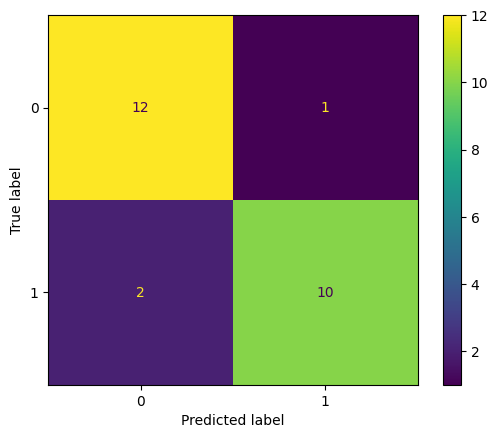

In [5]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
X, y = make_classification(random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    random_state=0)
clf = SVC(random_state=0)
clf.fit(X_train, y_train)
SVC(random_state=0)
predictions = clf.predict(X_test)
cm = confusion_matrix(y_test, predictions, labels=clf.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                               display_labels=clf.classes_)
disp.plot()

plt.show()

## F1, accuracy, recall, AUC and precision
Supplied cells. Two changes: I removed the leading space before `from` in the accuracy cell, and wrapped the multiclass model in `OneVsRestClassifier`.

In [6]:
from sklearn.metrics import f1_score

y_true = [0, 1, 2, 0, 1, 2]
y_pred = [0, 2, 1, 0, 0, 1]

print(f"Macro f1 score: {f1_score(y_true, y_pred, average='macro')}")

print(f"Micro F1: {f1_score(y_true, y_pred, average='micro')}")

print(f"Weighted Average F1: {f1_score(y_true, y_pred, average='weighted')}")

print(f"F1 No Average: {f1_score(y_true, y_pred, average=None)}")

y_true = [0, 0, 0, 0, 0, 0]
y_pred = [0, 0, 0, 0, 0, 0]
f1_score(y_true, y_pred, zero_division=1)

# multilabel classification
y_true = [[0, 0, 0], [1, 1, 1], [0, 1, 1]]
y_pred = [[0, 0, 0], [1, 1, 1], [1, 1, 0]]
print(f"F1 No Average: {f1_score(y_true, y_pred, average=None)}")

Macro f1 score: 0.26666666666666666
Micro F1: 0.3333333333333333
Weighted Average F1: 0.26666666666666666
F1 No Average: [0.8 0.  0. ]
F1 No Average: [0.66666667 1.         0.66666667]


In [7]:
# Changed: the supplied line began with a space (" from sklearn..."), which raises IndentationError
from sklearn.metrics import accuracy_score
y_pred = [0, 2, 1, 3]
y_true = [0, 1, 2, 3]
accuracy_score(y_true, y_pred)

0.5

In [8]:
from sklearn.metrics import precision_score
y_true = [0, 1, 2, 0, 1, 2]
y_pred = [0, 2, 1, 0, 0, 1]
precision_score(y_true, y_pred, average='macro')

0.2222222222222222

In [9]:
from sklearn.metrics import recall_score
y_true = [0, 1, 2, 0, 1, 2]
y_pred = [0, 2, 1, 0, 0, 1]
recall_score(y_true, y_pred, average='macro')

0.3333333333333333

In [10]:
from sklearn.metrics import classification_report
y_true = [0, 1, 2, 2, 2]
y_pred = [0, 0, 2, 2, 1]
target_names = ['class 0', 'class 1', 'class 2']
print(classification_report(y_true, y_pred, target_names=target_names))

              precision    recall  f1-score   support

     class 0       0.50      1.00      0.67         1
     class 1       0.00      0.00      0.00         1
     class 2       1.00      0.67      0.80         3

    accuracy                           0.60         5
   macro avg       0.50      0.56      0.49         5
weighted avg       0.70      0.60      0.61         5



In [11]:
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
X, y = load_breast_cancer(return_X_y=True)
clf = LogisticRegression(solver="liblinear", random_state=0).fit(X, y)
roc_auc_score(y, clf.predict_proba(X)[:, 1])

np.float64(0.994767718408118)

In [12]:
#multiclass case
# Changed: wrapped in OneVsRestClassifier to make the one-versus-rest strategy explicit and
# compatible with newer scikit-learn versions, which no longer accept liblinear for three classes
from sklearn.datasets import load_iris
from sklearn.multiclass import OneVsRestClassifier
X, y = load_iris(return_X_y=True)
clf = OneVsRestClassifier(LogisticRegression(solver="liblinear")).fit(X, y)
roc_auc_score(y, clf.predict_proba(X), multi_class='ovr')

np.float64(0.9913333333333334)

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import cycle

from sklearn import svm, datasets
from sklearn.metrics import roc_curve, auc
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import roc_auc_score

# Import some data to play with
iris = datasets.load_iris()
X = iris.data
y = iris.target

# Binarize the output
y = label_binarize(y, classes=[0, 1, 2])
n_classes = y.shape[1]

# Add noisy features to make the problem harder
random_state = np.random.RandomState(0)
n_samples, n_features = X.shape
X = np.c_[X, random_state.randn(n_samples, 200 * n_features)]

# shuffle and split training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=0)

# Learn to predict each class against the other
classifier = OneVsRestClassifier(
    svm.SVC(kernel="linear", probability=True, random_state=random_state)
)
y_score = classifier.fit(X_train, y_train).decision_function(X_test)

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute micro-average ROC curve and ROC area
fpr["micro"], tpr["micro"], _ = roc_curve(y_test.ravel(), y_score.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

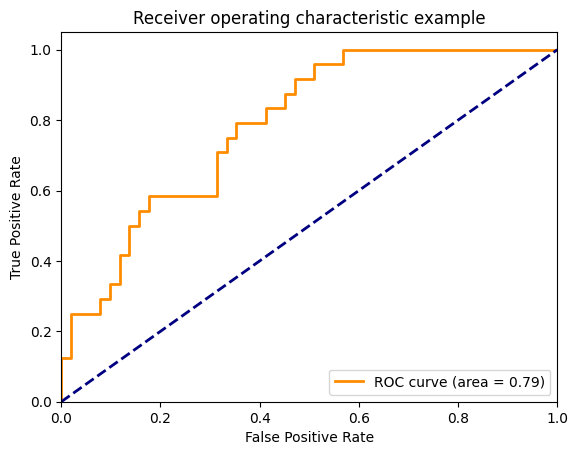

In [14]:
plt.figure()
lw = 2
plt.plot(
    fpr[2],
    tpr[2],
    color="darkorange",
    lw=lw,
    label="ROC curve (area = %0.2f)" % roc_auc[2],
)
plt.plot([0, 1], [0, 1], color="navy", lw=lw, linestyle="--")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver operating characteristic example")
plt.legend(loc="lower right")
plt.show()

In [15]:
from sklearn.metrics import log_loss
log_loss(["spam", "ham", "ham", "spam"], [[.1, .9], [.9, .1], [.8, .2], [.35, .65]])

0.21616187468057912

## Regression metrics
### The cell headed RMSE
Supplied cell, unchanged. `mean_squared_error` returns the mean squared error (MSE), not its root.

In [16]:
from sklearn.metrics import mean_squared_error
y_true = [3, -0.5, 2, 7]
y_pred = [2.5, 0.0, 2, 8]
mean_squared_error(y_true, y_pred)

0.375

In [17]:
# Added: the RMSE is the square root of the MSE above
print('MSE :', mean_squared_error(y_true, y_pred))
print('RMSE:', np.sqrt(mean_squared_error(y_true, y_pred)))

MSE : 0.375
RMSE: 0.6123724356957945


### MAE and R²
Supplied cells, unchanged.

In [18]:
from sklearn.metrics import mean_absolute_error
y_true = [3, -0.5, 2, 7]
y_pred = [2.5, 0.0, 2, 8]
mean_absolute_error(y_true, y_pred)

0.5

In [19]:
from sklearn.metrics import r2_score

r2_score(y_true, y_pred)

0.9486081370449679

# Part 2: changing parameters, effect on AUC
## 2a. Breast cancer: one model, training data against held-out data
In this data set class 1 is benign. I recode so that **1 means malignant**, the class a screening decision is about. AUC does not depend on which class is called positive, but thresholds do. I hold out 30% of cases, stratified, and keep them aside until the final test.

In [20]:
import json, pandas as pd
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
pd.set_option('display.width', 220)

data = load_breast_cancer()
Xb = data.data
yb = (data.target == 0).astype(int)          # 1 = malignant, 0 = benign
print('Cases:', len(yb), '| malignant:', int(yb.sum()), '| benign:', int((1 - yb).sum()))
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.3, stratify=yb, random_state=0)
print('Training cases:', len(yb_tr), '| held-out cases:', len(yb_te), f'({int(yb_te.sum())} malignant)')

def logreg(C=1.0, scaled=False):
    m = LogisticRegression(solver='liblinear', C=C, random_state=0)
    return make_pipeline(StandardScaler(), m) if scaled else m

# The supplied setting (C = 1, features as supplied), fitted once on the training cases
m = logreg().fit(Xb_tr, yb_tr)
same_fit = {'training AUC': roc_auc_score(yb_tr, m.predict_proba(Xb_tr)[:, 1]),
            'held-out AUC': roc_auc_score(yb_te, m.predict_proba(Xb_te)[:, 1])}
supplied = roc_auc_score(yb, logreg().fit(Xb, yb).predict_proba(Xb)[:, 1])
baseline = roc_auc_score(yb_te, DummyClassifier(strategy='prior').fit(Xb_tr, yb_tr).predict_proba(Xb_te)[:, 1])
print(f"Supplied method (fitted and scored on all 569 cases): {supplied:.4f}")
print(f"Same model fitted on the training cases: training AUC {same_fit['training AUC']:.4f}, held-out AUC {same_fit['held-out AUC']:.4f}")
print(f"Baseline that gives every case the same score: held-out AUC {baseline:.4f}")

Cases: 569 | malignant: 212 | benign: 357
Training cases: 398 | held-out cases: 171 (64 malignant)
Supplied method (fitted and scored on all 569 cases): 0.9945
Same model fitted on the training cases: training AUC 0.9931, held-out AUC 0.9955
Baseline that gives every case the same score: held-out AUC 0.5000


## 2b. Breast cancer: choosing C and scaling by cross-validation
Each setting is scored by 5-fold cross-validation **inside the training cases only**. The table is the sensitivity of AUC to the setting. The setting with the highest mean is then refitted on all training cases and tested once.

In [21]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
rows = []
for scaled in (False, True):
    for Cval in [0.001, 0.01, 0.1, 1, 10, 100]:
        s = cross_val_score(logreg(Cval, scaled), Xb_tr, yb_tr, cv=cv, scoring='roc_auc')
        rows.append({'features': 'scaled' if scaled else 'as supplied', 'C': Cval,
                     'CV AUC mean': round(s.mean(), 4), 'CV AUC sd': round(s.std(), 4)})
cv_C = pd.DataFrame(rows)
print(cv_C.to_string(index=False))
best = cv_C.loc[cv_C['CV AUC mean'].idxmax()]
print(f"\nChosen by cross-validation: C = {best.C}, features {best.features}")
chosen = logreg(best.C, best.features == 'scaled').fit(Xb_tr, yb_tr)
p_mal = chosen.predict_proba(Xb_te)[:, 1]
final_auc = roc_auc_score(yb_te, p_mal)
print(f"Final test, once: held-out AUC {final_auc:.4f}, held-out accuracy {chosen.score(Xb_te, yb_te):.4f}")

   features       C  CV AUC mean  CV AUC sd
as supplied   0.001       0.9682     0.0287
as supplied   0.010       0.9754     0.0234
as supplied   0.100       0.9855     0.0115
as supplied   1.000       0.9915     0.0048
as supplied  10.000       0.9903     0.0051
as supplied 100.000       0.9911     0.0048
     scaled   0.001       0.9887     0.0071
     scaled   0.010       0.9945     0.0059
     scaled   0.100       0.9964     0.0051
     scaled   1.000       0.9977     0.0037
     scaled  10.000       0.9959     0.0045
     scaled 100.000       0.9944     0.0055

Chosen by cross-validation: C = 1.0, features scaled
Final test, once: held-out AUC 0.9917, held-out accuracy 0.9532


## 2c. Breast cancer: one AUC, different decisions
The thresholds below were fixed before the test as illustrations, not chosen from the results: 0.5 (the default), 0.3 and 0.1. AUC is the same at every threshold, because it ranks the scores; the threshold turns them into decisions.

Held-out AUC 0.9917 at every threshold
 threshold  cancers found  cancers missed  false alarms  true negatives  sensitivity  specificity
       0.5             60               4             4             103        0.938        0.963
       0.3             61               3            10              97        0.953        0.907
       0.1             63               1            14              93        0.984        0.869


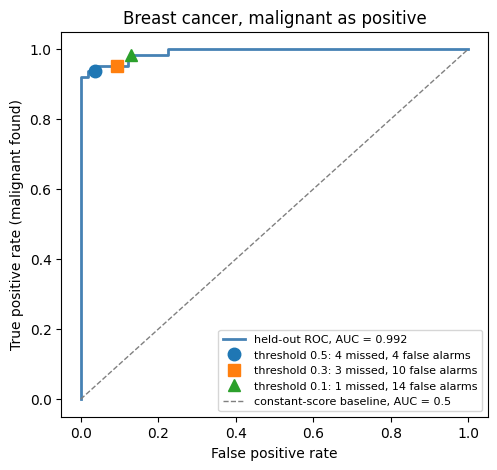

In [22]:
THRESHOLDS = [0.5, 0.3, 0.1]   # fixed before the test
rows = []
for t in THRESHOLDS:
    flag = p_mal >= t
    tp, fn = int((flag & (yb_te == 1)).sum()), int((~flag & (yb_te == 1)).sum())
    fp, tn = int((flag & (yb_te == 0)).sum()), int((~flag & (yb_te == 0)).sum())
    rows.append({'threshold': t, 'cancers found': tp, 'cancers missed': fn, 'false alarms': fp, 'true negatives': tn,
                 'sensitivity': round(tp / (tp + fn), 3), 'specificity': round(tn / (tn + fp), 3)})
thresholds = pd.DataFrame(rows)
print(f'Held-out AUC {final_auc:.4f} at every threshold')
print(thresholds.to_string(index=False))

fpr_b, tpr_b, _ = roc_curve(yb_te, p_mal)
plt.figure(figsize=(5.5, 5))
plt.plot(fpr_b, tpr_b, color='steelblue', lw=2, label=f'held-out ROC, AUC = {final_auc:.3f}')
for t, mk in zip(THRESHOLDS, ['o', 's', '^']):
    r = thresholds[thresholds.threshold == t].iloc[0]
    plt.plot(1 - r.specificity, r.sensitivity, mk, ms=9,
             label=f'threshold {t}: {int(r["cancers missed"])} missed, {int(r["false alarms"])} false alarms')
plt.plot([0, 1], [0, 1], '--', color='grey', lw=1, label='constant-score baseline, AUC = 0.5')
plt.xlabel('False positive rate'); plt.ylabel('True positive rate (malignant found)')
plt.title('Breast cancer, malignant as positive'); plt.legend(loc='lower right', fontsize=8); plt.show()

## 2d. Iris with noise: nested noise columns over five seeds
The supplied ROC cell adds 800 random features to the 4 real ones. Here each seed draws 800 noise columns once, and each width uses the first 0, 40, 200 or 800 of them, so a wider setting extends a narrower one. I repeat this for five seeds and report the mean and spread of the class-2 and micro-average AUC, for three values of the SVC's C. The data split is the supplied one throughout.

In [23]:
iris = datasets.load_iris()
yi = label_binarize(iris.target, classes=[0, 1, 2])
rows = []
for seed in range(5):
    noise_all = np.random.RandomState(seed).randn(iris.data.shape[0], 800)
    for k in [0, 40, 200, 800]:
        Xi = np.c_[iris.data, noise_all[:, :k]]
        Xtr, Xte, ytr, yte = train_test_split(Xi, yi, test_size=0.5, random_state=0)
        for Cval in [0.01, 1, 100]:
            s = OneVsRestClassifier(svm.SVC(kernel='linear', C=Cval)).fit(Xtr, ytr).decision_function(Xte)
            rows.append({'seed': seed, 'noise features': k, 'C': Cval,
                         'class 2': roc_auc_score(yte[:, 2], s[:, 2]), 'micro': roc_auc_score(yte.ravel(), s.ravel())})
noise = pd.DataFrame(rows)
noise_summary = noise.groupby(['noise features', 'C']).agg(
    class2_mean=('class 2', 'mean'), class2_sd=('class 2', 'std'), class2_min=('class 2', 'min'), class2_max=('class 2', 'max'),
    micro_mean=('micro', 'mean'), micro_sd=('micro', 'std')).round(4).reset_index()
print(noise_summary.to_string(index=False))

 noise features      C  class2_mean  class2_sd  class2_min  class2_max  micro_mean  micro_sd
              0   0.01       0.9681     0.0000      0.9681      0.9681      0.8063    0.0000
              0   1.00       0.9951     0.0000      0.9951      0.9951      0.9390    0.0000
              0 100.00       0.9975     0.0000      0.9975      0.9975      0.9591    0.0000
             40   0.01       0.8814     0.0349      0.8276      0.9183      0.7625    0.0152
             40   1.00       0.8471     0.0242      0.8096      0.8766      0.7581    0.0256
             40 100.00       0.8471     0.0242      0.8096      0.8766      0.7546    0.0233
            200   0.01       0.8219     0.0464      0.7549      0.8783      0.7718    0.0336
            200   1.00       0.8219     0.0485      0.7549      0.8873      0.7688    0.0350
            200 100.00       0.8219     0.0485      0.7549      0.8873      0.7688    0.0350
            800   0.01       0.7647     0.0313      0.7239      0.8039

# Part 3: changing parameters, effect on R²
## 3a. The supplied four numbers
R² compares the errors with those of always predicting the mean. I change one prediction at a time.

In [24]:
y_true = [3, -0.5, 2, 7]
cases = {
    'supplied predictions': [2.5, 0.0, 2, 8],
    'last prediction 8 -> 10': [2.5, 0.0, 2, 10],
    'last prediction 8 -> 4': [2.5, 0.0, 2, 4],
    'always predict the mean (2.875)': [2.875] * 4,
    'predictions reversed': [8, 2, 0.0, 2.5],
}
rows = [{'case': k, 'R2': round(r2_score(y_true, v), 4), 'RMSE': round(float(np.sqrt(mean_squared_error(y_true, v))), 4),
         'MAE': round(mean_absolute_error(y_true, v), 4)} for k, v in cases.items()]
print(pd.DataFrame(rows).to_string(index=False))

                           case      R2   RMSE   MAE
           supplied predictions  0.9486 0.6124 0.500
        last prediction 8 -> 10  0.6745 1.5411 1.000
         last prediction 8 -> 4  0.6745 1.5411 1.000
always predict the mean (2.875)  0.0000 2.7013 2.125
           predictions reversed -0.9015 3.7249 3.500


## 3b. Diabetes data: choosing Ridge alpha by cross-validation
scikit-learn's diabetes data: 442 patients, 10 measurements, disease progression after one year. I hold out 30%, score each alpha by 5-fold cross-validation inside the training cases, refit the best and test it once, against a baseline that always predicts the training mean.

In [25]:
from sklearn.datasets import load_diabetes
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.preprocessing import PolynomialFeatures
Xd, yd = load_diabetes(return_X_y=True)
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, yd, test_size=0.3, random_state=0)
kf = KFold(n_splits=5, shuffle=True, random_state=0)
rmse = lambda a, b: float(np.sqrt(mean_squared_error(a, b)))
print('Training cases:', len(yd_tr), '| held-out cases:', len(yd_te), f'| target mean {yd.mean():.1f}, standard deviation {yd.std():.1f}')

rows = []
for alpha in [0.001, 0.01, 0.1, 1, 10, 100]:
    s = cross_val_score(Ridge(alpha=alpha), Xd_tr, yd_tr, cv=kf, scoring='r2')
    rows.append({'alpha': alpha, 'CV R2 mean': round(s.mean(), 4), 'CV R2 sd': round(s.std(), 4)})
cv_alpha = pd.DataFrame(rows)
print(cv_alpha.to_string(index=False))
best_alpha = cv_alpha.loc[cv_alpha['CV R2 mean'].idxmax(), 'alpha']
ridge = Ridge(alpha=best_alpha).fit(Xd_tr, yd_tr)
mean_pred = np.full(len(yd_te), yd_tr.mean())
final_ridge = {'alpha': best_alpha, 'held-out R2': r2_score(yd_te, ridge.predict(Xd_te)), 'held-out RMSE': rmse(yd_te, ridge.predict(Xd_te)),
               'baseline R2': r2_score(yd_te, mean_pred), 'baseline RMSE': rmse(yd_te, mean_pred)}
print(f"\nChosen by cross-validation: alpha = {best_alpha}")
print(f"Final test, once: held-out R2 {final_ridge['held-out R2']:.4f}, RMSE {final_ridge['held-out RMSE']:.2f}")
print(f"Baseline (training mean): held-out R2 {final_ridge['baseline R2']:.4f}, RMSE {final_ridge['baseline RMSE']:.2f}")

Training cases: 309 | held-out cases: 133 | target mean 152.1, standard deviation 77.0
  alpha  CV R2 mean  CV R2 sd
  0.001      0.5012    0.0729
  0.010      0.5033    0.0726
  0.100      0.5053    0.0601
  1.000      0.4076    0.0647
 10.000      0.1179    0.0365
100.000     -0.0055    0.0224

Chosen by cross-validation: alpha = 0.1
Final test, once: held-out R2 0.4021, RMSE 55.23
Baseline (training mean): held-out R2 -0.0000, RMSE 71.42


## 3c. Diabetes data: polynomial degree
For degrees 1 to 3, I report cross-validated R² inside the training cases, the fit on all training cases, and the rank of the training design: when the rank is below the number of features, the features are not independent and the least-squares fit is not unique. The held-out score is shown for comparison only; it is not used to choose anything.

In [26]:
rows = []
for degree in [1, 2, 3]:
    model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
    s = cross_val_score(model, Xd_tr, yd_tr, cv=kf, scoring='r2')
    model.fit(Xd_tr, yd_tr)
    design = PolynomialFeatures(degree).fit_transform(Xd_tr)
    rows.append({'degree': degree, 'features': design.shape[1], 'design rank': int(np.linalg.matrix_rank(design)),
                 'CV R2 mean': round(s.mean(), 4), 'CV R2 sd': round(s.std(), 4),
                 'training R2': round(r2_score(yd_tr, model.predict(Xd_tr)), 4),
                 'held-out R2': round(r2_score(yd_te, model.predict(Xd_te)), 4)})
degree_table = pd.DataFrame(rows)
print(degree_table.to_string(index=False))

 degree  features  design rank  CV R2 mean  CV R2 sd  training R2  held-out R2
      1        11           11      0.5006    0.0724       0.5539       0.3929
      2        66           65      0.2669    0.1765       0.6570       0.2254
      3       286          275   -252.0112  160.0128       0.9473     -65.8505


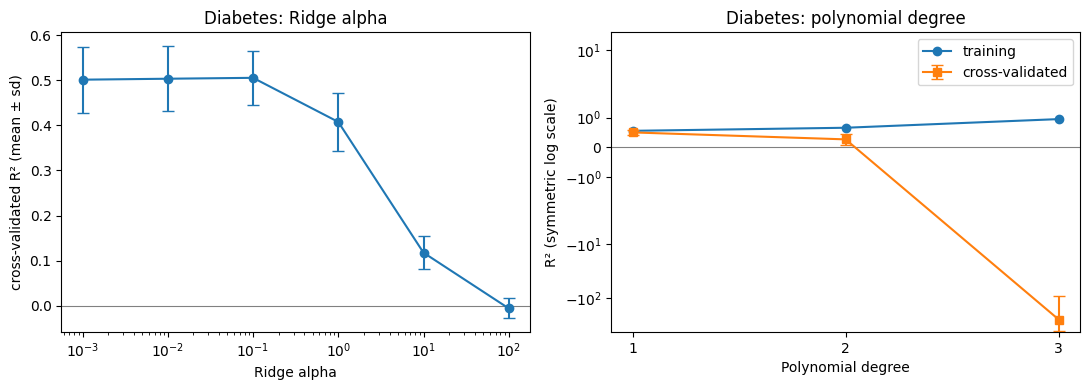

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].errorbar(cv_alpha.alpha, cv_alpha['CV R2 mean'], yerr=cv_alpha['CV R2 sd'], fmt='o-', capsize=4)
axes[0].set_xscale('log'); axes[0].axhline(0, color='grey', lw=0.8)
axes[0].set_xlabel('Ridge alpha'); axes[0].set_ylabel('cross-validated R² (mean ± sd)'); axes[0].set_title('Diabetes: Ridge alpha')
axes[1].plot(degree_table.degree, degree_table['training R2'], 'o-', label='training')
axes[1].errorbar(degree_table.degree, degree_table['CV R2 mean'], yerr=degree_table['CV R2 sd'], fmt='s-', capsize=4, label='cross-validated')
axes[1].set_xticks([1, 2, 3]); axes[1].set_yscale('symlog'); axes[1].axhline(0, color='grey', lw=0.8)
axes[1].set_xlabel('Polynomial degree'); axes[1].set_ylabel('R² (symmetric log scale)'); axes[1].set_title('Diabetes: polynomial degree'); axes[1].legend()
plt.tight_layout(); plt.show()

## Summary of results

In [28]:
import platform, sklearn
summary = {
    'expectations': EXPECT,
    'breast_cancer': {'supplied method': round(supplied, 4), **{k: round(v, 4) for k, v in same_fit.items()},
                      'baseline': round(baseline, 4), 'chosen': {'C': float(best.C), 'features': best.features},
                      'final held-out AUC': round(final_auc, 4)},
    'cv_C': cv_C.to_dict(orient='records'),
    'thresholds': thresholds.to_dict(orient='records'),
    'noise_summary': noise_summary.to_dict(orient='records'),
    'cv_alpha': cv_alpha.to_dict(orient='records'),
    'final_ridge': {k: (round(v, 4) if isinstance(v, float) else v) for k, v in final_ridge.items()},
    'degree': degree_table.to_dict(orient='records'),
    'versions': {'python': platform.python_version(), 'scikit-learn': sklearn.__version__, 'numpy': np.__version__},
}
print(json.dumps(summary, indent=1, default=str))

{
 "expectations": {
  "Breast cancer: AUC on held-out data compared with the supplied AUC on the training data": "I\u2019d expect held-out AUC to be slightly lower because the supplied AUC was measured on training data.",
  "Iris ROC: effect of adding more random noise features on the AUC": "Adding irrelevant features would likely lower Iris AUC.",
  "Diabetes: effect of a larger Ridge alpha (stronger regularisation) on the test R2": "A small increase in Ridge alpha might make little difference to held-out R\u00b2, but a large increase would likely lower it through underfitting."
 },
 "breast_cancer": {
  "supplied method": 0.9945,
  "training AUC": 0.9931,
  "held-out AUC": 0.9955,
  "baseline": 0.5,
  "chosen": {
   "C": 1.0,
   "features": "scaled"
  },
  "final held-out AUC": 0.9917
 },
 "cv_C": [
  {
   "features": "as supplied",
   "C": 0.001,
   "CV AUC mean": 0.9682,
   "CV AUC sd": 0.0287
  },
  {
   "features": "as supplied",
   "C": 0.01,
   "CV AUC mean": 0.9754,
   "CV AU